# Sequential vs parallel quicksort: where is the threshold?

**Question:** from which array size does `parallelQuicksort` (pthreads, `THREAD_LEVEL=10`) beat the sequential quicksort on this machine?

**Machine:** Intel Core i7-1185G7 (4 cores / 8 hardware threads), Linux 7.0, gcc 13.3, governor `powersave`, laptop on normal desktop load.
**Binary:** `src/parallelQuicksort` compiled with the repository Makefile (`-O0 -g`).

**Protocol** (`scripts/run_threshold_benchmark.sh`):
- 26 sizes log-spaced from $10^2$ to $10^7$, 20 repetitions each, so 520 runs.
- The run order is **shuffled**, so drift over time (temperature, background jobs) is spread evenly across sizes.
- In each run, the program sorts the *same* random array with the sequential, parallel and libc `qsort` versions. This means sequential and parallel can be compared **run by run** (paired).

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "lines.linewidth": 2})
COLORS = {"Sequential": "#2a78d6", "Parallel": "#eb6834", "Built-in": "#1baf7a"}

path = sorted(glob.glob("data/*_2026-10-18/threshold_*.csv"))[-1]
df = pd.read_csv(path)
print(path, df.shape)
print(open(path.rsplit("/", 1)[0] + "/environment.txt").read())
df.head()

data/yassine-HP-EliteBook-840-G8-Notebook-PC_2026-10-18/threshold_1717.csv (1560, 4)
CPU(s):                                  8
Model name:                              11th Gen Intel(R) Core(TM) i7-1185G7 @ 3.00GHz
Thread(s) per core:                      2
Core(s) per socket:                      4
CPU(s) scaling MHz:                      55%
7.0.0-38-generic
gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
powersave
 17:17:46 up  2:24,  1 user,  load average: 1.22, 1.33, 0.95



,run,size,type,time
0,1,25119,Sequential,0.004348
1,1,25119,Parallel,0.047385
2,1,25119,Built-in,0.003997
3,2,251,Sequential,0.000028
4,2,251,Parallel,0.009844


## 1. Sanity checks
Every (size, type) pair should have 20 measurements, and the run order should really be mixed.

In [2]:
print(df.groupby(["size", "type"]).size().unstack().describe().loc[["min", "max"]])
order = df[df.type == "Sequential"][["run", "size"]]
print("Spearman corr(run index, size) =", round(stats.spearmanr(order["run"], order["size"])[0], 3))

type  Built-in  Parallel  Sequential
min       20.0      20.0        20.0
max       20.0      20.0        20.0
Spearman corr(run index, size) = 0.039


## 2. Raw execution times
Both axes are log scale. Dots are individual runs, lines are medians.

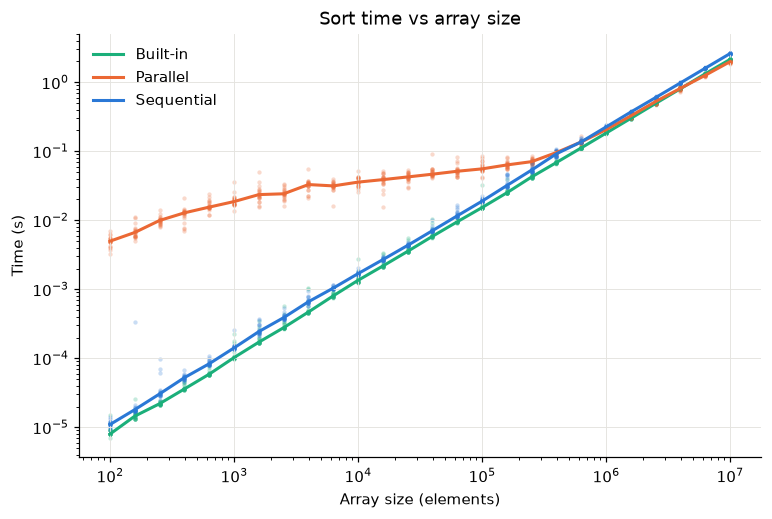

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for t, g in df.groupby("type"):
    ax.scatter(g["size"], g.time, s=8, alpha=0.25, color=COLORS[t], linewidths=0)
    med = g.groupby("size").time.median()
    ax.plot(med.index, med.values, color=COLORS[t], label=t)
ax.set(xscale="log", yscale="log", xlabel="Array size (elements)", ylabel="Time (s)",
       title="Sort time vs array size")
ax.legend(frameon=False)
plt.show()

For small arrays, the parallel version has a near-constant cost of about **5–50 ms**. This is thread overhead: with `THREAD_LEVEL=10` the recursion creates up to $2^{11}-1 = 2047$ threads, whatever the array size. Sequential time grows roughly as $n \log n$, and the two curves only meet around $10^5$–$10^6$ elements.

## 3. Speed-up = Sequential / Parallel (paired per run)
For each run we compute `seq_time / par_time` on the same input. The band is a bootstrap 95% confidence interval of the median speed-up.

In [4]:
w = df.pivot_table(index=["run", "size"], columns="type", values="time").reset_index()
w["speedup"] = w.Sequential / w.Parallel

rng = np.random.default_rng(0)
def boot_ci(x, n=5000):
    meds = np.median(rng.choice(x, (n, len(x))), axis=1)
    return np.percentile(meds, [2.5, 97.5])

rows = []
for s, g in w.groupby("size"):
    lo, hi = boot_ci(g.speedup.values)
    p = stats.wilcoxon(g.Sequential, g.Parallel, alternative="greater").pvalue
    rows.append(dict(size=s, median_speedup=g.speedup.median(), ci_low=lo, ci_high=hi,
                     frac_par_faster=(g.speedup > 1).mean(), wilcoxon_p=p))
sp = pd.DataFrame(rows)
sp.style.format({"median_speedup": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}",
                 "frac_par_faster": "{:.0%}", "wilcoxon_p": "{:.1e}"})

,size,median_speedup,ci_low,ci_high,frac_par_faster,wilcoxon_p
0,100,0.002,0.002,0.002,0%,1.0e+00
1,158,0.003,0.002,0.003,0%,1.0e+00
2,251,0.003,0.003,0.003,0%,1.0e+00
3,398,0.004,0.004,0.005,0%,1.0e+00
4,631,0.005,0.005,0.006,0%,1.0e+00
5,1000,0.008,0.007,0.008,0%,1.0e+00
6,1585,0.011,0.010,0.012,0%,1.0e+00
7,2512,0.016,0.015,0.018,0%,1.0e+00
8,3981,0.021,0.019,0.023,0%,1.0e+00
9,6310,0.033,0.031,0.034,0%,1.0e+00


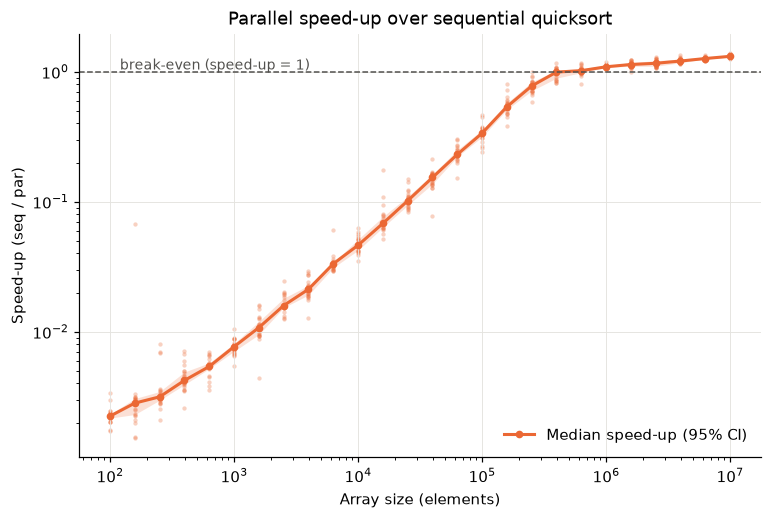

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(sp["size"], sp.ci_low, sp.ci_high, color=COLORS["Parallel"], alpha=0.2, linewidth=0)
ax.scatter(w["size"], w.speedup, s=8, alpha=0.3, color=COLORS["Parallel"], linewidths=0)
ax.plot(sp["size"], sp.median_speedup, color=COLORS["Parallel"], marker="o", markersize=4, label="Median speed-up (95% CI)")
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.text(1.2e2, 1.04, "break-even (speed-up = 1)", color="#52514e", fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="Array size (elements)", ylabel="Speed-up (seq / par)",
       title="Parallel speed-up over sequential quicksort")
ax.legend(frameon=False, loc="lower right")
plt.show()

## 4. Estimating the threshold

In [6]:

x, y = np.log10(sp["size"].values), np.log(sp.median_speedup.values)
i = np.where((y[:-1] < 0) & (y[1:] >= 0))[0][0]
cross = 10 ** (x[i] - y[i] * (x[i+1] - x[i]) / (y[i+1] - y[i]))

above = sp.ci_low > 1
safe = sp["size"][above & above[::-1].cummin()[::-1]].min()

print(f"Median break-even (interpolated): ~{cross:,.0f} elements")
print(f"Parallel significantly faster (CI > 1 for all larger sizes): from {safe:,} elements")
print(f"Max median speed-up observed: {sp.median_speedup.max():.2f}x at n = {sp.loc[sp.median_speedup.idxmax(), 'size']:,}")

Median break-even (interpolated): ~443,077 elements
Parallel significantly faster (CI > 1 for all larger sizes): from 1,000,000 elements
Max median speed-up observed: 1.31x at n = 10,000,000


## 5. Conclusion

- **Up to ~250k elements, sequential always wins** (in 100% of the runs). For small arrays it wins by orders of magnitude (~130× at $n=10^3$), because creating ~2000 threads dominates the run time.
- **Break-even is at roughly 0.4 - 0.6 M elements** (about 3 to 5 MB of doubles); the interpolated median crossing is at about 440k. At $n \approx 4\times10^5$ and $6.3\times10^5$ each version wins about half of the runs, and the difference is not significant.
- **From $10^6$ elements on, parallel is reliably faster**: it wins ≥95% of the runs (p < 1e-5), and the confidence interval stays above 1 for every larger size.
- **The gain is modest:** about 1.3× at $10^7$ on 4 cores / 8 threads. Likely causes, in this code rather than in the machine:
  - the first `partition` call(s) run alone on a single thread (Amdahl);
  - `partition` calls `rand()`, which is protected by a global lock in glibc, so threads contend on it (the run spent ~7.5 min in *sys* time out of ~9 min of *user* time);
  - `THREAD_LEVEL=10` launches 2047 threads for 8 hardware threads;
  - the code is compiled with `-O0`.

**Limits of this experiment:** one machine, `powersave` governor (frequency scaling and turbo are uncontrolled), a laptop under normal desktop load, and a single input distribution (uniform random doubles). The threshold depends on `THREAD_LEVEL` and on the compiler flags, so it should be measured again if either one changes.

# Part 2: very large arrays (10M to 200M)

Before, the biggest size was 10M and the speed-up was only ~1.3x. Here I go further to see if parallel gets better with much bigger arrays.

Sizes: 10M, 20M, 50M, 100M, 200M, 5 runs each, random order (`scripts/run_large_benchmark.sh`). I stopped at 200M because the program needs ~24 bytes per element (two arrays + qsort buffer), so ~5 GB, and each run already takes a few minutes.

In [7]:
path_l = sorted(glob.glob("data/*/large_*.csv"))[-1]
dl = pd.read_csv(path_l)
print(path_l, dl.shape)
print(open(path_l.rsplit("/", 1)[0] + "/environment.txt").read())
dl.groupby(["size", "type"]).time.agg(["count", "median", "min", "max"]).unstack("type")

data/yassine-HP-EliteBook-840-G8-Notebook-PC_2026-10-22/large_1034.csv (75, 4)
CPU(s):                                  8
Model name:                              11th Gen Intel(R) Core(TM) i7-1185G7 @ 3.00GHz
Thread(s) per core:                      2
Core(s) per socket:                      4
CPU(s) scaling MHz:                      26%
               total        used        free      shared  buff/cache   available
Mem:              31           4          24           0           3          26
7.0.0-38-generic
gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
powersave
AC online: 0
 10:34:57 up 42 min,  1 user,  load average: 0.17, 0.32, 0.70



count                         median                        \
type      Built-in Parallel Sequential   Built-in   Parallel Sequential   
size                                                                      
10000000         5        5          5   2.107232   1.937868   2.619245   
20000000         5        5          5   4.427888   4.034962   5.430048   
50000000         5        5          5  11.836261   9.940420  14.319917   
100000000        5        5          5  25.131213  20.679505  29.457397   
200000000        5        5          5  52.613064  47.861631  62.695530   

                 min                                max                        
type        Built-in   Parallel Sequential     Built-in   Parallel Sequential  
size                                                                           
10000000    2.088079   1.898051   2.579051     2.293857   2.072685   2.722400  
20000000    4.383935   3.835591   5.325801     4.545954   4.216855   5.527079  
50000000   11.561761   9.116309  14.139772  2390.552489  10.151311  14.502457  
100000000  24.120626  20.191285  29.045638    26.314613  21.029011  30.468657  
200000000  50.440087  42.467859  60.360569    53.118967  48.574155  63.103186

One Built-in run at 50M took ~2390 s instead of ~12 s. The system log shows the laptop went to sleep at 10:59, right during that run (it was on battery), and `gettimeofday` counts the sleeping time. So I remove this measurement.

In [8]:
med = dl.groupby(["size", "type"]).time.transform("median")
print(dl[dl.time > 5 * med])
dl = dl[dl.time <= 5 * med]

    run      size      type         time
71   24  50000000  Built-in  2390.552489


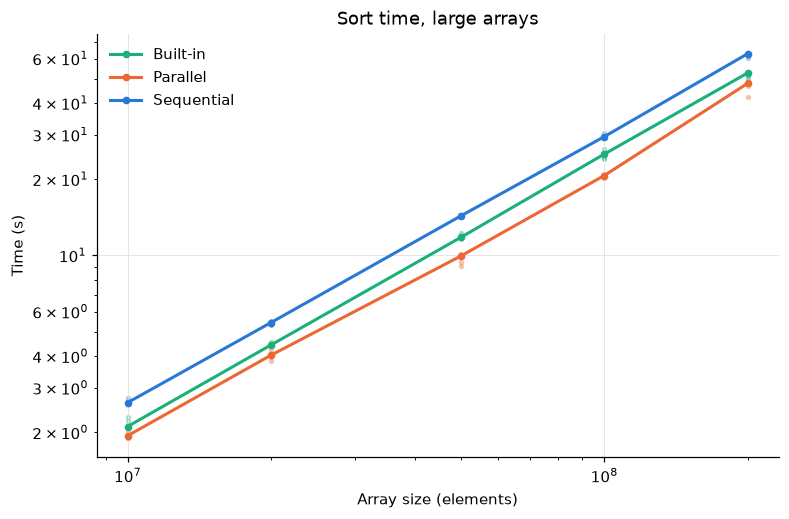

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for t, g in dl.groupby("type"):
    ax.scatter(g["size"], g.time, s=12, alpha=0.4, color=COLORS[t], linewidths=0)
    med = g.groupby("size").time.median()
    ax.plot(med.index, med.values, color=COLORS[t], marker="o", markersize=4, label=t)
ax.set(xscale="log", yscale="log", xlabel="Array size (elements)", ylabel="Time (s)",
       title="Sort time, large arrays")
ax.legend(frameon=False)
plt.show()

In [10]:
wl = dl.pivot_table(index=["run", "size"], columns="type", values="time").reset_index()
wl["par_vs_seq"] = wl.Sequential / wl.Parallel
wl["par_vs_builtin"] = wl["Built-in"] / wl.Parallel
spl = wl.groupby("size")[["par_vs_seq", "par_vs_builtin"]].agg(["median", "min", "max"])
spl

type      par_vs_seq                     par_vs_builtin                    
              median       min       max         median       min       max
size                                                                       
10000000    1.351612  1.251452  1.428195       1.103994  1.016668  1.183701
20000000    1.367814  1.277826  1.420085       1.097808  1.039622  1.185203
50000000    1.458938  1.410647  1.563358       1.225699  1.155886  1.310632
100000000   1.426054  1.417631  1.448887       1.201905  1.175062  1.266385
200000000   1.318450  1.273021  1.421324       1.101665  1.057837  1.187724

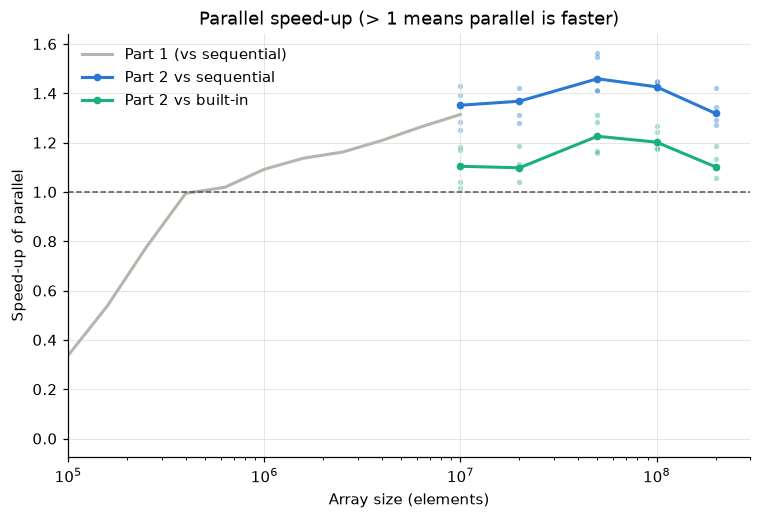

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
# small-array run for comparison (from part 1)
ax.plot(sp["size"], sp.median_speedup, color="#b5b4ad", label="Part 1 (vs sequential)")
for col, lab, c in [("par_vs_seq", "vs sequential", COLORS["Sequential"]),
                    ("par_vs_builtin", "vs built-in", COLORS["Built-in"])]:
    ax.scatter(wl["size"], wl[col], s=12, alpha=0.4, color=c, linewidths=0)
    m = wl.groupby("size")[col].median()
    ax.plot(m.index, m.values, color=c, marker="o", markersize=4, label="Part 2 " + lab)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.set(xscale="log", xlabel="Array size (elements)", ylabel="Speed-up of parallel",
       title="Parallel speed-up (> 1 means parallel is faster)", xlim=(1e5, 3e8))
ax.legend(frameon=False)
plt.show()

## Conclusion (part 2)

- Parallel is the fastest of the three at every size from 10M to 200M, in all the runs.
- But it doesn't really get better with bigger arrays: the speed-up vs sequential stays between ~1.3x and ~1.45x (best around 50M), and vs built-in only ~1.1–1.2x. It even goes down a bit at 200M.
- So going bigger is not enough. **Why?** This is not proven yet, but I think it's mostly the code:
  - With 4 real cores (8 with hyperthreading), ~3–4x should be possible. Even if the first partitions are done by only 1, then 2, then 4 threads, the theory still allows much more than 1.4x.
  - `partition` calls `rand()` to choose the pivot. In glibc, `rand()` has **one single lock** shared by all threads (they all use the same hidden random state). It is called once per partition, so millions of times, and the threads keep waiting for each other to get this lock.
  - A quick test at 20M with `/usr/bin/time` supports this: 44 s of user time but **37 s of system time** and ~1.3 million context switches. A sort should almost never go into the kernel, so this looks like threads blocked on a lock.
  - `THREAD_LEVEL=10` creates ~2000 threads for 8 hardware threads, which adds creation/scheduling cost.
  - Rabii's machine has more CPUs (12) and gets worse results, so more cores alone don't help.
- Resources can still play a part: the laptop was on battery (the CPU was limited to ~1.3 GHz), it slows down when all cores are busy, 8 CPUs are really 4 cores, and the cores share memory bandwidth.
- To check: change only the code (use `rand_r` with one seed per thread, compile with `-O2`) and see if the speed-up jumps, then change only the resources (charger plugged in, sleep disabled, another machine).